<a href="https://colab.research.google.com/github/GeiseEduardo1973/Engenharia-de-Software-Ci-ncia-da-Computa-o/blob/main/Exerc%C3%ADcio_tema_3_IA_Aplicada_%C3%A0_vis%C3%A3o_Computacional1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 57s 60ms/step - accuracy: 0.9456 - loss: 0.1871 - val_accuracy: 0.9836 - val_loss: 0.0521
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 58ms/step - accuracy: 0.9839 - loss: 0.0519 - val_accuracy: 0.9854 - val_loss: 0.0453
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 58ms/step - accuracy: 0.9880 - loss: 0.0378 - val_accuracy: 0.9890 - val_loss: 0.0322
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 54s 58ms/step - accuracy: 0.9903 - loss: 0.0298 - val_accuracy: 0.9879 - val_loss: 0.0319
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 58ms/step - accuracy: 0.9926 - loss: 0.0232 - val_accuracy: 0.9905 - val_loss: 0.0299
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


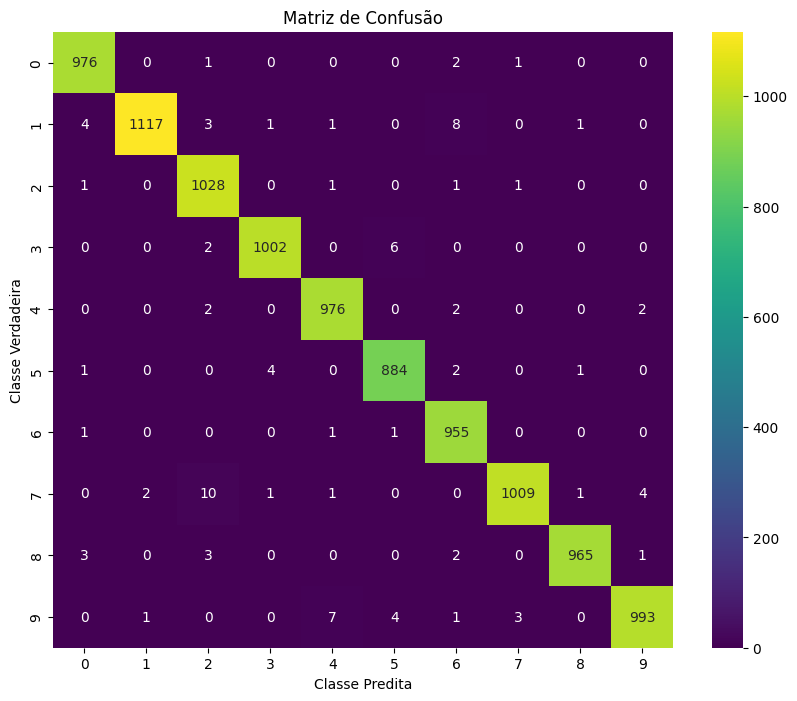

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
from keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

# Carregar dados MNIST
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# Pré-processamento dos dados
# Redimensionar e normalizar as imagens de treinamento e teste
train_images = train_images.reshape((60000, 28, 28, 1)).astype('float32') / 255
test_images = test_images.reshape((10000, 28, 28, 1)).astype('float32') / 255

# Converter rótulos em codificação one-hot
train_labels = tf.keras.utils.to_categorical(train_labels)
test_labels = tf.keras.utils.to_categorical(test_labels)

# Construir o modelo CNN
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),  # Camada convolucional com 32 filtros de tamanho 3x3
    layers.MaxPooling2D((2, 2)),  # Camada de pooling para redução de dimensionalidade
    layers.Conv2D(64, (3, 3), activation='relu'),  # Segunda camada convolucional com 64 filtros de tamanho 3x3
    layers.MaxPooling2D((2, 2)),  # Outra camada de pooling
    layers.Conv2D(64, (3, 3), activation='relu'),  # Terceira camada convolucional com 64 filtros de tamanho 3x3
    layers.Flatten(),  # Achatamento dos dados para entrada na camada densa
    layers.Dense(64, activation='relu'),  # Camada densa com 64 unidades e função de ativação ReLU
    layers.Dense(10, activation='softmax')  # Camada de saída com 10 unidades para classificação de 10 classes e função de ativação softmax
])

# Compilar o modelo
model.compile(optimizer='adam',  # Otimizador Adam
              loss='categorical_crossentropy',  # Função de perda para classificação categórica
              metrics=['accuracy'])  # Métrica de avaliação da acurácia

# Treinar o modelo
model.fit(train_images, train_labels, epochs=5, batch_size=64, validation_data=(test_images, test_labels))

import seaborn as sns
# Fazer previsões no conjunto de teste
predictions = model.predict(test_images)

# Converter previsões em rótulos
predicted_labels = np.argmax(predictions, axis=1)
true_labels = np.argmax(test_labels, axis=1)

# Calcular a matriz de confusão (tabela de correlação)
confusion_matrix = tf.math.confusion_matrix(labels=true_labels, predictions=predicted_labels)

# Plotar a matriz de confusão como um gráfico de calor usando seaborn com cores vibrantes
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='viridis')  # Ajuste da paleta de cores para 'viridis'
plt.xlabel('Classe Predita')
plt.ylabel('Classe Verdadeira')
plt.title('Matriz de Confusão')
plt.show()


